In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os, zipfile, warnings
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import torchvision.models as models
import pandas as pd
warnings.filterwarnings('ignore')

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {device}")

Device: cuda


In [ ]:
zip_path     = '/content/drive/MyDrive/CASIA_B/casia-b-silhouettes.zip'
extract_path = '/content/CASIA_B'

if not os.path.exists(extract_path):
    print("Extracting...")
    with zipfile.ZipFile(zip_path, 'r') as zf:
        zf.extractall(extract_path)
    print("Done.")
else:
    print("Already extracted.")

subjects = sorted(os.listdir(extract_path))
print(f"Subjects: {len(subjects)}")

Already extracted.
Subjects: 124


In [ ]:
TRAIN_SUBJECTS = [f'{i:03d}' for i in range(1,  75)]
TEST_SUBJECTS  = [f'{i:03d}' for i in range(75, 125)]

GALLERY_SEQS   = ['nm-01','nm-02','nm-03','nm-04']
PROBE_NM       = ['nm-05','nm-06']
PROBE_BG       = ['bg-01','bg-02']
PROBE_CL       = ['cl-01','cl-02']
ALL_PROBE_SEQS = PROBE_NM + PROBE_BG + PROBE_CL

ANGLES = ['000','018','036','054','072',
          '090','108','126','144','162','180']

# Image size — tall enough to split into meaningful strips
IMG_H      = 128    # height
IMG_W      = 64     # width
IMG_SIZE   = (IMG_W, IMG_H)   # PIL uses (W, H)
N_PARTS    = 4      # horizontal strips
PART_H     = IMG_H // N_PARTS   # 32px per strip — enough context
BATCH_SIZE = 32
NUM_EPOCHS = 50

train_label_map = {s: i for i, s in enumerate(sorted(TRAIN_SUBJECTS))}
test_label_map  = {s: i for i, s in enumerate(sorted(TEST_SUBJECTS))}
NUM_TRAIN_CLASSES = len(TRAIN_SUBJECTS)   # 74
NUM_TEST_CLASSES  = len(TEST_SUBJECTS)    # 50

print(f"IMG_SIZE  : {IMG_SIZE} (W x H)")
print(f"N_PARTS   : {N_PARTS}")
print(f"PART_H    : {PART_H}px per strip")
print(f"Train cls : {NUM_TRAIN_CLASSES}")
print(f"Test  cls : {NUM_TEST_CLASSES}")

IMG_SIZE  : (64, 128) (W x H)
N_PARTS   : 4
PART_H    : 32px per strip
Train cls : 74
Test  cls : 50


In [ ]:
def load_silhouettes(folder_path):
    """Load silhouettes at IMG_SIZE resolution."""
    frames = []
    valid  = ('.png', '.jpg', '.bmp')
    files  = sorted([f for f in os.listdir(folder_path)
                     if f.lower().endswith(valid)])
    for fname in files:
        img = Image.open(
            os.path.join(folder_path, fname)
        ).convert('L').resize(IMG_SIZE, Image.BILINEAR)
        frames.append(np.array(img, dtype=np.float32))
    return frames   # each frame: (IMG_H, IMG_W)


def compute_gei(frames):
    """Average frames into a single GEI, normalised to [0,1]."""
    if not frames:
        return None
    stack = np.stack(frames, axis=0)
    gei   = np.mean(stack, axis=0)
    mn, mx = gei.min(), gei.max()
    return ((gei - mn) / (mx - mn + 1e-8)).astype(np.float32)


def split_gei_parts(gei, n_parts):
    """
    Split GEI into n_parts horizontal strips of EXACTLY equal height.
    Crops the GEI to the largest multiple of n_parts that fits in IMG_H,
    so every strip has identical shape regardless of n_parts value.

    Returns array of shape (n_parts, strip_h, IMG_W)
    where strip_h = (IMG_H // n_parts)
    """
    H       = gei.shape[0]
    strip_h = H // n_parts          # integer division -> exact
    usable  = strip_h * n_parts     # may be < H if not divisible

    # Crop from top to ensure all strips are exactly strip_h tall
    gei_cropped = gei[:usable, :]   # (usable, IMG_W)

    parts = []
    for p in range(n_parts):
        s = p * strip_h
        e = s + strip_h
        parts.append(gei_cropped[s:e, :])   # (strip_h, IMG_W)

    stacked = np.stack(parts, axis=0)       # (n_parts, strip_h, IMG_W)
    return stacked


print("Core functions defined.")
print(f"IMG_H={IMG_H}, IMG_W={IMG_W}")
print(f"Default N_PARTS={N_PARTS} -> strip_h={IMG_H//N_PARTS}px")
print(f"N=2 -> strip_h={IMG_H//2}px")
print(f"N=6 -> strip_h={IMG_H//6}px")

Core functions defined.
IMG_H=128, IMG_W=64
Default N_PARTS=4 -> strip_h=32px
N=2 -> strip_h=64px
N=6 -> strip_h=21px


In [ ]:
sample_path = os.path.join(extract_path, '001', 'nm-01', '090')
frames_vis  = load_silhouettes(sample_path)
gei_vis     = compute_gei(frames_vis)
parts_vis   = split_gei_parts(gei_vis, N_PARTS)

print(f"GEI shape   : {gei_vis.shape}")
print(f"Parts shape : {parts_vis.shape}")

part_labels = ['Part 1: Head/Shoulders',
               'Part 2: Torso',
               'Part 3: Hips/Thighs',
               'Part 4: Legs/Feet']
colors = ['#e74c3c','#e67e22','#27ae60','#2980b9']

fig, axes = plt.subplots(1, N_PARTS + 1, figsize=(14, 5))

# Full GEI with strip boundaries
axes[0].imshow(gei_vis, cmap='gray', aspect='auto')
for p in range(N_PARTS):
    axes[0].axhline(p * PART_H, color=colors[p],
                    linewidth=2, linestyle='--')
axes[0].set_title('Full GEI\n(128×64)', fontsize=10)
axes[0].axis('off')

# Individual strips — displayed at TRUE aspect ratio
for p in range(N_PARTS):
    axes[p+1].imshow(parts_vis[p], cmap='gray',
                     aspect='auto', vmin=0, vmax=1)
    axes[p+1].set_title(
        f'{part_labels[p]}\n({PART_H}×{IMG_W})', fontsize=8
    )
    axes[p+1].axis('off')

plt.suptitle(
    'Subject 001 | NM-01 | 90° — Part Strips (No Distortion)',
    fontsize=11, fontweight='bold'
)
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/CASIA_B/part_strips_vis.png',
            dpi=150, bbox_inches='tight')
plt.show()
print("Saved.")

GEI shape   : (128, 64)
Parts shape : (4, 32, 64)


Saved.


In [ ]:
conditions_vis = [
    ('nm-01', 'Normal'),
    ('bg-01', 'Bag'),
    ('cl-01', 'Coat'),
]

fig, axes = plt.subplots(3, N_PARTS + 1, figsize=(14, 10))

for row, (cond, label) in enumerate(conditions_vis):
    path = os.path.join(extract_path, '001', cond, '090')
    if not os.path.exists(path):
        continue
    gei   = compute_gei(load_silhouettes(path))
    parts = split_gei_parts(gei, N_PARTS)

    axes[row, 0].imshow(gei, cmap='gray', aspect='auto')
    axes[row, 0].set_title(f'{label}\nFull GEI', fontsize=9)
    axes[row, 0].axis('off')

    for p in range(N_PARTS):
        axes[row, p+1].imshow(
            parts[p], cmap='gray',
            aspect='auto', vmin=0, vmax=1
        )
        axes[row, p+1].set_title(
            f'{label}\nPart {p+1}', fontsize=9
        )
        axes[row, p+1].axis('off')

plt.suptitle(
    'Part Strips Across Conditions | Subject 001 | 90°',
    fontsize=11, fontweight='bold'
)
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/CASIA_B/part_conditions.png',
            dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
class CASIABDataset(Dataset):
    """
    Returns:
      mode='full'  -> tensor (1, IMG_H, IMG_W)   standard GEI
      mode='parts' -> tensor (N_PARTS, PART_H, IMG_W)  strips
    """
    def __init__(self, root, subjects, sequences, angles,
                 label_map=None, mode='full', n_parts=N_PARTS):
        self.samples  = []
        self.mode     = mode
        self.n_parts  = n_parts

        if label_map is None:
            label_map = {s: i for i, s
                         in enumerate(sorted(subjects))}
        num_cls = len(label_map)
        skipped = 0

        for subj in sorted(subjects):
            if subj not in label_map:
                skipped += 1; continue
            lbl = label_map[subj]
            if not (0 <= lbl < num_cls):
                skipped += 1; continue

            for seq in sequences:
                for angle in angles:
                    folder = os.path.join(
                        root, subj, seq, angle
                    )
                    if not os.path.exists(folder):
                        continue
                    frames = load_silhouettes(folder)
                    if not frames:
                        continue
                    gei = compute_gei(frames)
                    if gei is None:
                        continue

                    if mode == 'full':
                        inp = gei[np.newaxis, :]      # (1,H,W)
                    else:
                        inp = split_gei_parts(
                            gei, n_parts
                        )                             # (P,ph,W)

                    cond = ('NM' if 'nm' in seq
                            else 'BG' if 'bg' in seq
                            else 'CL')
                    self.samples.append((
                        inp.astype(np.float32),
                        int(lbl), cond, angle
                    ))

        print(f"  Loaded {len(self.samples)} samples "
              f"({skipped} skipped) "
              f"[mode={mode}, n_parts={n_parts}]")

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        inp, lbl, cond, angle = self.samples[idx]
        return (torch.tensor(inp,  dtype=torch.float32),
                torch.tensor(lbl,  dtype=torch.long),
                cond, angle)

print("CASIABDataset defined.")

CASIABDataset defined.


In [ ]:
class FullGEINet(nn.Module):
    """ResNet-18 on full GEI (1-channel, 128×64)."""
    def __init__(self, num_classes=74):
        super().__init__()
        base = models.resnet18(
            weights=models.ResNet18_Weights.DEFAULT
        )
        base.conv1 = nn.Conv2d(
            1, 64, kernel_size=7,
            stride=2, padding=3, bias=False
        )
        base.fc = nn.Linear(512, num_classes)
        self.net = base

    def forward(self, x):
        return self.net(x)

    def extract(self, x):
        n = self.net
        x = n.maxpool(n.relu(n.bn1(n.conv1(x))))
        x = n.layer4(n.layer3(n.layer2(n.layer1(x))))
        return torch.flatten(n.avgpool(x), 1)   # (B,512)

print("FullGEINet defined.")

FullGEINet defined.


In [ ]:
class PartEncoder(nn.Module):
    """
    Lightweight CNN for a single horizontal strip.
    Input: (B, 1, PART_H, IMG_W)  e.g. (B,1,32,64)
    Output: (B, 256) feature vector
    """
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            # Block 1
            nn.Conv2d(1, 32, 3, padding=1), nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.Conv2d(32, 32, 3, padding=1), nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),                        # /2

            # Block 2
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.Conv2d(64, 64, 3, padding=1), nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),                        # /2

            # Block 3
            nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.AdaptiveAvgPool2d((1, 1)),           # -> (B,128,1,1)
            nn.Flatten(),                           # -> (B,128)
            nn.Linear(128, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.net(x)


class PartGEINet(nn.Module):
    """
    One PartEncoder per body part (NOT shared weights).
    Separate encoders allow each body region to learn
    region-specific features.
    Part features are concatenated then classified.
    """
    def __init__(self, num_classes=74, n_parts=N_PARTS,
                 use_part_attention=True):
        super().__init__()
        self.n_parts           = n_parts
        self.use_part_attention = use_part_attention

        # One dedicated encoder per part
        self.encoders = nn.ModuleList(
            [PartEncoder() for _ in range(n_parts)]
        )

        # Optional: learnable part attention weights
        # Lower body parts (indices 2,3) get higher init weights
        if use_part_attention:
            init_w = torch.ones(n_parts)
            init_w[n_parts-1] = 2.0   # legs/feet
            init_w[n_parts-2] = 1.5   # hips/thighs
            self.attn = nn.Parameter(init_w)
        else:
            self.attn = None

        feat_dim = 256 * n_parts

        # Classification head
        self.classifier = nn.Sequential(
            nn.Linear(feat_dim, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(inplace=True),
            nn.Dropout(0.4),
            nn.Linear(512, num_classes)
        )

    def _encode_parts(self, x):
        """x: (B, n_parts, PART_H, IMG_W)"""
        B = x.size(0)
        feats = []
        for p in range(self.n_parts):
            xp = x[:, p:p+1, :, :]     # (B,1,PART_H,W)
            f  = self.encoders[p](xp)   # (B,256)
            if self.attn is not None:
                w = torch.sigmoid(self.attn[p])
                f = f * w
            feats.append(f)
        return torch.cat(feats, dim=1)  # (B, 256*n_parts)

    def forward(self, x):
        return self.classifier(self._encode_parts(x))

    def extract(self, x):
        return self._encode_parts(x)    # (B, 256*n_parts)

print("PartGEINet defined.")
print(f"  Part feature dim : 256 × {N_PARTS} = {256*N_PARTS}")

PartGEINet defined.
  Part feature dim : 256 × 4 = 1024


In [ ]:
class AugmentedDataset(Dataset):
    """
    Wraps CASIABDataset and applies on-the-fly augmentation
    during training only:
      - Random horizontal flip (gait is symmetric)
      - Random noise
      - Random brightness jitter
    """
    def __init__(self, base_ds, augment=True):
        self.base    = base_ds
        self.augment = augment

    def __len__(self):
        return len(self.base)

    def __getitem__(self, idx):
        inp, lbl, cond, angle = self.base[idx]
        if self.augment:
            # Random horizontal flip
            if torch.rand(1).item() > 0.5:
                inp = torch.flip(inp, dims=[-1])
            # Random Gaussian noise
            if torch.rand(1).item() > 0.5:
                noise = torch.randn_like(inp) * 0.02
                inp   = (inp + noise).clamp(0, 1)
            # Random brightness
            if torch.rand(1).item() > 0.5:
                factor = 0.8 + torch.rand(1).item() * 0.4
                inp    = (inp * factor).clamp(0, 1)
        return inp, lbl, cond, angle

print("AugmentedDataset defined.")

AugmentedDataset defined.


In [ ]:
def train_model(model, loader, num_epochs=50,
                lr=1e-3, num_classes=74):
    criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
    optimizer = optim.AdamW(
        model.parameters(), lr=lr, weight_decay=1e-4
    )
    scheduler = optim.lr_scheduler.CosineAnnealingLR(
        optimizer, T_max=num_epochs, eta_min=1e-5
    )
    history = {'loss': [], 'acc': []}

    for epoch in range(num_epochs):
        model.train()
        running_loss, correct, total = 0.0, 0, 0

        for inp, lbl, _, _ in loader:
            if (lbl.max().item() >= num_classes
                    or lbl.min().item() < 0):
                continue
            inp = inp.to(device)
            lbl = lbl.to(device)

            optimizer.zero_grad()
            out  = model(inp)
            loss = criterion(out, lbl)
            loss.backward()
            nn.utils.clip_grad_norm_(
                model.parameters(), max_norm=5.0
            )
            optimizer.step()

            running_loss += loss.item()
            _, pred = out.max(1)
            correct += pred.eq(lbl).sum().item()
            total   += lbl.size(0)

        scheduler.step()
        if total > 0:
            ep_loss = running_loss / len(loader)
            ep_acc  = 100. * correct / total
            history['loss'].append(ep_loss)
            history['acc'].append(ep_acc)
            if (epoch + 1) % 5 == 0:
                print(f"  Epoch [{epoch+1:>2}/{num_epochs}]"
                      f"  Loss: {ep_loss:.4f}"
                      f"  Acc: {ep_acc:.2f}%")

    return model, history

print("train_model defined.")

train_model defined.


In [ ]:
@torch.no_grad()
def extract_features(model, dataset):
    loader = DataLoader(
        dataset, batch_size=64,
        shuffle=False, num_workers=2
    )
    feats, lbls, conds, angs = [], [], [], []
    model.eval()
    for inp, lbl, cond, ang in loader:
        f = model.extract(inp.to(device)).cpu().numpy()
        feats.append(f)
        lbls.extend(lbl.numpy())
        conds.extend(cond)
        angs.extend(ang)
    return (np.concatenate(feats, 0),
            np.array(lbls), conds, angs)


def evaluate_rank1(model, gallery_ds, probe_ds,
                   exclude_same_angle=True):
    gal_f, gal_l, _,       gal_a = extract_features(
        model, gallery_ds
    )
    prb_f, prb_l, prb_c, prb_a   = extract_features(
        model, probe_ds
    )
    # L2 normalise for cosine similarity
    gal_f /= (np.linalg.norm(gal_f,axis=1,keepdims=True)+1e-8)
    prb_f /= (np.linalg.norm(prb_f,axis=1,keepdims=True)+1e-8)

    results = {'NM':[],'BG':[],'CL':[]}

    for i in range(len(prb_f)):
        sims = gal_f @ prb_f[i]
        if exclude_same_angle:
            mask = np.array([a != prb_a[i] for a in gal_a])
            if mask.sum() == 0:
                mask = np.ones(len(gal_a), dtype=bool)
            sims = np.where(mask, sims, -np.inf)
        pred = gal_l[np.argmax(sims)]
        results[prb_c[i]].append(int(pred == prb_l[i]))

    rank1 = {c: 100.*np.mean(v) if v else 0.
             for c, v in results.items()}
    rank1['Mean'] = float(np.mean(list(rank1.values())))
    return rank1

print("Evaluation functions defined.")

Evaluation functions defined.


In [ ]:
print("Building all datasets...\n")

# ── Training ──────────────────────────────────────────────
print("[1/6] Train — Full GEI")
tr_full_ds = CASIABDataset(
    extract_path, TRAIN_SUBJECTS,
    GALLERY_SEQS + ALL_PROBE_SEQS, ANGLES,
    label_map=train_label_map, mode='full'
)
tr_full_aug = AugmentedDataset(tr_full_ds, augment=True)
ldr_full    = DataLoader(
    tr_full_aug, batch_size=BATCH_SIZE,
    shuffle=True, num_workers=2, pin_memory=True
)

print("[2/6] Train — Part GEI")
tr_part_ds = CASIABDataset(
    extract_path, TRAIN_SUBJECTS,
    GALLERY_SEQS + ALL_PROBE_SEQS, ANGLES,
    label_map=train_label_map,
    mode='parts', n_parts=N_PARTS
)
tr_part_aug = AugmentedDataset(tr_part_ds, augment=True)
ldr_part    = DataLoader(
    tr_part_aug, batch_size=BATCH_SIZE,
    shuffle=True, num_workers=2, pin_memory=True
)

# ── Test Gallery ───────────────────────────────────────────
print("[3/6] Test Gallery — Full GEI")
gal_full = CASIABDataset(
    extract_path, TEST_SUBJECTS,
    GALLERY_SEQS, ANGLES,
    label_map=test_label_map, mode='full'
)
print("[4/6] Test Gallery — Part GEI")
gal_part = CASIABDataset(
    extract_path, TEST_SUBJECTS,
    GALLERY_SEQS, ANGLES,
    label_map=test_label_map,
    mode='parts', n_parts=N_PARTS
)

# ── Test Probe ─────────────────────────────────────────────
print("[5/6] Test Probe — Full GEI")
prb_full = CASIABDataset(
    extract_path, TEST_SUBJECTS,
    ALL_PROBE_SEQS, ANGLES,
    label_map=test_label_map, mode='full'
)
print("[6/6] Test Probe — Part GEI")
prb_part = CASIABDataset(
    extract_path, TEST_SUBJECTS,
    ALL_PROBE_SEQS, ANGLES,
    label_map=test_label_map,
    mode='parts', n_parts=N_PARTS
)

print("\nAll datasets ready.")

Building all datasets...

[1/6] Train — Full GEI
  Loaded 8107 samples (0 skipped) [mode=full, n_parts=4]
[2/6] Train — Part GEI
  Loaded 8107 samples (0 skipped) [mode=parts, n_parts=4]
[3/6] Test Gallery — Full GEI
  Loaded 2187 samples (0 skipped) [mode=full, n_parts=4]
[4/6] Test Gallery — Part GEI
  Loaded 2187 samples (0 skipped) [mode=parts, n_parts=4]
[5/6] Test Probe — Full GEI
  Loaded 3298 samples (0 skipped) [mode=full, n_parts=4]
[6/6] Test Probe — Part GEI
  Loaded 3298 samples (0 skipped) [mode=parts, n_parts=4]

All datasets ready.


In [ ]:
print("="*55)
print("BASELINE: Full GEI — ResNet-18")
print("="*55)

model_base = FullGEINet(
    num_classes=NUM_TRAIN_CLASSES
).to(device)

model_base, hist_base = train_model(
    model_base, ldr_full,
    num_epochs=NUM_EPOCHS, lr=1e-3,
    num_classes=NUM_TRAIN_CLASSES
)

torch.save(
    model_base.state_dict(),
    '/content/drive/MyDrive/CASIA_B/model_baseline.pth'
)
print("Saved.")

BASELINE: Full GEI — ResNet-18
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 152MB/s]


  Epoch [ 5/50]  Loss: 0.9508  Acc: 97.10%
  Epoch [10/50]  Loss: 0.8269  Acc: 99.56%
  Epoch [15/50]  Loss: 0.8087  Acc: 99.79%
  Epoch [20/50]  Loss: 0.7649  Acc: 99.98%
  Epoch [25/50]  Loss: 0.7580  Acc: 100.00%
  Epoch [30/50]  Loss: 0.7536  Acc: 100.00%
  Epoch [35/50]  Loss: 0.7512  Acc: 100.00%
  Epoch [40/50]  Loss: 0.7493  Acc: 100.00%
  Epoch [45/50]  Loss: 0.7485  Acc: 100.00%
  Epoch [50/50]  Loss: 0.7481  Acc: 100.00%
Saved.


In [ ]:
rank1_base = evaluate_rank1(model_base, gal_full, prb_full)
print("BASELINE Results:")
for c in ['NM','BG','CL','Mean']:
    print(f"  {c}: {rank1_base[c]:.2f}%")

BASELINE Results:
  NM: 93.82%
  BG: 72.13%
  CL: 33.82%
  Mean: 66.59%


In [ ]:
print("="*55)
print(f"PROPOSED: Part-GEI N={N_PARTS} — Dedicated Encoders")
print("="*55)

model_part = PartGEINet(
    num_classes=NUM_TRAIN_CLASSES,
    n_parts=N_PARTS,
    use_part_attention=True
).to(device)

model_part, hist_part = train_model(
    model_part, ldr_part,
    num_epochs=NUM_EPOCHS, lr=1e-3,
    num_classes=NUM_TRAIN_CLASSES
)

torch.save(
    model_part.state_dict(),
    '/content/drive/MyDrive/CASIA_B/model_part_gei.pth'
)
print("Saved.")

PROPOSED: Part-GEI N=4 — Dedicated Encoders
  Epoch [ 5/50]  Loss: 1.2046  Acc: 92.20%
  Epoch [10/50]  Loss: 0.9758  Acc: 98.51%
  Epoch [15/50]  Loss: 0.9129  Acc: 99.47%
  Epoch [20/50]  Loss: 0.8804  Acc: 99.70%
  Epoch [25/50]  Loss: 0.8565  Acc: 99.93%
  Epoch [30/50]  Loss: 0.8381  Acc: 99.96%
  Epoch [35/50]  Loss: 0.8270  Acc: 100.00%
  Epoch [40/50]  Loss: 0.8174  Acc: 100.00%
  Epoch [45/50]  Loss: 0.8126  Acc: 100.00%
  Epoch [50/50]  Loss: 0.8112  Acc: 100.00%
Saved.


In [ ]:
rank1_part = evaluate_rank1(model_part, gal_part, prb_part)
print("PROPOSED Part-GEI Results:")
for c in ['NM','BG','CL','Mean']:
    print(f"  {c}: {rank1_part[c]:.2f}%")

print("\nDelta vs Baseline:")
for c in ['NM','BG','CL','Mean']:
    d = rank1_part[c] - rank1_base[c]
    print(f"  {c}: {'+' if d>=0 else ''}{d:.2f}%")

PROPOSED Part-GEI Results:
  NM: 99.00%
  BG: 91.44%
  CL: 52.55%
  Mean: 80.99%

Delta vs Baseline:
  NM: +5.18%
  BG: +19.31%
  CL: +18.73%
  Mean: +14.41%


In [ ]:
df_main = pd.DataFrame([
    {'Method': 'Standard GEI [Baseline]',
     'NM (%)': round(rank1_base['NM'],  2),
     'BG (%)': round(rank1_base['BG'],  2),
     'CL (%)': round(rank1_base['CL'],  2),
     'Mean (%)': round(rank1_base['Mean'],2)},
    {'Method': f'Part-GEI N={N_PARTS} + Attention [Proposed]',
     'NM (%)': round(rank1_part['NM'],  2),
     'BG (%)': round(rank1_part['BG'],  2),
     'CL (%)': round(rank1_part['CL'],  2),
     'Mean (%)': round(rank1_part['Mean'],2)},
])
df_main.to_csv(
    '/content/drive/MyDrive/CASIA_B/main_results.csv',
    index=False
)
print("Main Results:")
print(df_main.to_string(index=False))

Main Results:
                             Method  NM (%)  BG (%)  CL (%)  Mean (%)
            Standard GEI [Baseline]   93.82   72.13   33.82     66.59
Part-GEI N=4 + Attention [Proposed]   99.00   91.44   52.55     80.99


In [ ]:
print("Ablation: Part Attention ON vs OFF\n")

model_noattn = PartGEINet(
    num_classes=NUM_TRAIN_CLASSES,
    n_parts=N_PARTS,
    use_part_attention=False
).to(device)
model_noattn, _ = train_model(
    model_noattn, ldr_part,
    num_epochs=NUM_EPOCHS, lr=1e-3,
    num_classes=NUM_TRAIN_CLASSES
)
rank1_noattn = evaluate_rank1(
    model_noattn, gal_part, prb_part
)
torch.save(
    model_noattn.state_dict(),
    '/content/drive/MyDrive/CASIA_B/model_part_noattn.pth'
)
print("No-Attention Results:")
for c in ['NM','BG','CL','Mean']:
    print(f"  {c}: {rank1_noattn[c]:.2f}%")

del model_noattn
torch.cuda.empty_cache()

Ablation: Part Attention ON vs OFF

  Epoch [ 5/50]  Loss: 1.2095  Acc: 91.81%
  Epoch [10/50]  Loss: 0.9798  Acc: 98.45%
  Epoch [15/50]  Loss: 0.9106  Acc: 99.54%
  Epoch [20/50]  Loss: 0.8751  Acc: 99.79%
  Epoch [25/50]  Loss: 0.8550  Acc: 99.95%
  Epoch [30/50]  Loss: 0.8374  Acc: 99.99%
  Epoch [35/50]  Loss: 0.8242  Acc: 100.00%
  Epoch [40/50]  Loss: 0.8157  Acc: 100.00%
  Epoch [45/50]  Loss: 0.8112  Acc: 100.00%
  Epoch [50/50]  Loss: 0.8094  Acc: 100.00%
No-Attention Results:
  NM: 99.73%
  BG: 92.08%
  CL: 55.00%
  Mean: 82.27%


In [ ]:
ablation_results = {
    'Baseline (N=1)'              : rank1_base,
    f'Part-GEI N={N_PARTS} + Attn' : rank1_part,
    f'Part-GEI N={N_PARTS} No-Attn': rank1_noattn,
}

for N_abl in [2, 6]:
    print(f"\n{'='*40}  N={N_abl}")
    print(f"  strip_h = {IMG_H // N_abl}px")

    # Verify strip height is valid before building dataset
    strip_h_abl = IMG_H // N_abl
    assert strip_h_abl >= 8, \
        f"strip_h={strip_h_abl} too small for N={N_abl}"

    ds_tr = CASIABDataset(
        extract_path, TRAIN_SUBJECTS,
        GALLERY_SEQS + ALL_PROBE_SEQS, ANGLES,
        label_map=train_label_map,
        mode='parts', n_parts=N_abl
    )

    # Verify all samples have consistent shape
    shapes = set(s[0].shape for s in ds_tr.samples)
    print(f"  Unique input shapes in train: {shapes}")
    assert len(shapes) == 1, \
        f"Inconsistent shapes found: {shapes}"

    aug_ds = AugmentedDataset(ds_tr, augment=True)
    ldr    = DataLoader(
        aug_ds, batch_size=BATCH_SIZE,
        shuffle=True, num_workers=2, pin_memory=True
    )

    mdl = PartGEINet(
        num_classes=NUM_TRAIN_CLASSES,
        n_parts=N_abl,
        use_part_attention=True
    ).to(device)

    mdl, _ = train_model(
        mdl, ldr, num_epochs=NUM_EPOCHS,
        lr=1e-3, num_classes=NUM_TRAIN_CLASSES
    )

    gal = CASIABDataset(
        extract_path, TEST_SUBJECTS,
        GALLERY_SEQS, ANGLES,
        label_map=test_label_map,
        mode='parts', n_parts=N_abl
    )
    prb = CASIABDataset(
        extract_path, TEST_SUBJECTS,
        ALL_PROBE_SEQS, ANGLES,
        label_map=test_label_map,
        mode='parts', n_parts=N_abl
    )

    # Verify test shapes too
    gal_shapes = set(s[0].shape for s in gal.samples)
    prb_shapes = set(s[0].shape for s in prb.samples)
    print(f"  Gallery shapes: {gal_shapes}")
    print(f"  Probe   shapes: {prb_shapes}")

    r = evaluate_rank1(mdl, gal, prb)
    ablation_results[f'Part-GEI N={N_abl} + Attn'] = r
    print(f"  NM={r['NM']:.2f}  BG={r['BG']:.2f}"
          f"  CL={r['CL']:.2f}  Mean={r['Mean']:.2f}")

    torch.save(
        mdl.state_dict(),
        f'/content/drive/MyDrive/CASIA_B/model_N{N_abl}.pth'
    )
    del mdl
    torch.cuda.empty_cache()

print("\nAblation complete.")


========================================  N=2
  strip_h = 64px
  Loaded 8107 samples (0 skipped) [mode=parts, n_parts=2]
  Unique input shapes in train: {(2, 64, 64)}
  Epoch [ 5/50]  Loss: 1.4690  Acc: 81.56%
  Epoch [10/50]  Loss: 1.0318  Acc: 97.00%
  Epoch [15/50]  Loss: 0.9339  Acc: 99.32%
  Epoch [20/50]  Loss: 0.8981  Acc: 99.57%
  Epoch [25/50]  Loss: 0.8639  Acc: 99.93%
  Epoch [30/50]  Loss: 0.8476  Acc: 99.99%
  Epoch [35/50]  Loss: 0.8342  Acc: 99.99%
  Epoch [40/50]  Loss: 0.8248  Acc: 100.00%
  Epoch [45/50]  Loss: 0.8204  Acc: 99.99%
  Epoch [50/50]  Loss: 0.8174  Acc: 100.00%
  Loaded 2187 samples (0 skipped) [mode=parts, n_parts=2]
  Loaded 3298 samples (0 skipped) [mode=parts, n_parts=2]
  Gallery shapes: {(2, 64, 64)}
  Probe   shapes: {(2, 64, 64)}
  NM=99.00  BG=91.99  CL=49.82  Mean=80.27

========================================  N=6
  strip_h = 21px
  Loaded 8107 samples (0 skipped) [mode=parts, n_parts=6]
  Unique input shapes in train: {(6, 21, 64)}
  Epoch [

Ablation Table:
              Method  NM (%)  BG (%)  CL (%)  Mean (%)
      Baseline (N=1)   93.82   72.13   33.82     66.59
 Part-GEI N=2 + Attn   99.00   91.99   49.82     80.27
Part-GEI N=4 No-Attn   99.73   92.08   55.00     82.27
 Part-GEI N=4 + Attn   99.00   91.44   52.55     80.99
 Part-GEI N=6 + Attn   99.27   92.90   53.00     81.72


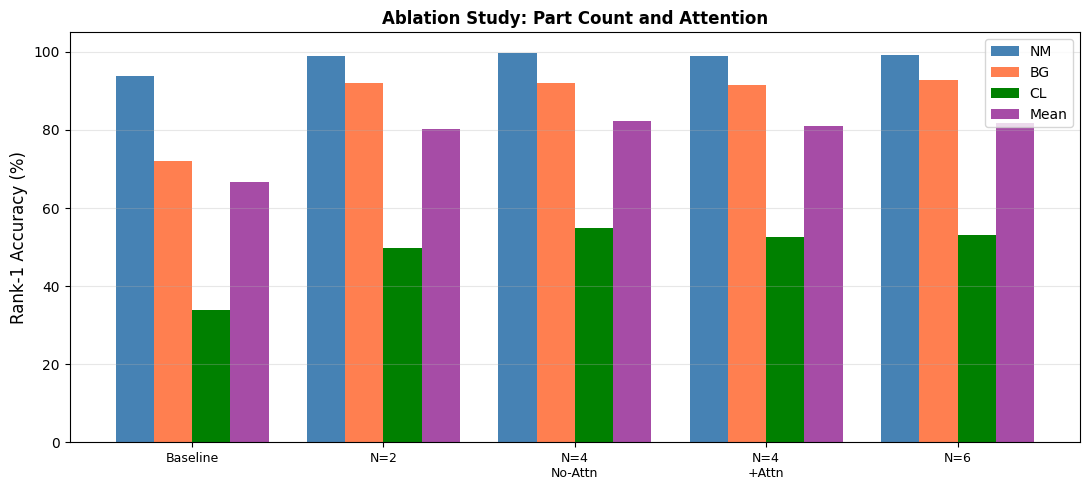

In [ ]:
abl_order = [
    'Baseline (N=1)',
    'Part-GEI N=2 + Attn',
    f'Part-GEI N={N_PARTS} No-Attn',
    f'Part-GEI N={N_PARTS} + Attn',
    'Part-GEI N=6 + Attn',
]
rows = []
for k in abl_order:
    if k not in ablation_results: continue
    r = ablation_results[k]
    rows.append({'Method': k,
                 'NM (%)' : round(r['NM'],  2),
                 'BG (%)' : round(r['BG'],  2),
                 'CL (%)' : round(r['CL'],  2),
                 'Mean (%)': round(r['Mean'],2)})

df_abl = pd.DataFrame(rows)
df_abl.to_csv(
    '/content/drive/MyDrive/CASIA_B/ablation.csv',
    index=False
)
print("Ablation Table:")
print(df_abl.to_string(index=False))

# Plot
methods_plot = [
    ('Baseline',   rank1_base),
    ('N=2',        ablation_results.get('Part-GEI N=2 + Attn',{})),
    (f'N={N_PARTS}\nNo-Attn',
                   ablation_results.get(
                       f'Part-GEI N={N_PARTS} No-Attn',{})),
    (f'N={N_PARTS}\n+Attn', rank1_part),
    ('N=6',        ablation_results.get('Part-GEI N=6 + Attn',{})),
]
x  = np.arange(len(methods_plot))
w  = 0.2
nm = [v.get('NM',0) for _,v in methods_plot]
bg = [v.get('BG',0) for _,v in methods_plot]
cl = [v.get('CL',0) for _,v in methods_plot]
mn = [v.get('Mean',0) for _,v in methods_plot]

fig, ax = plt.subplots(figsize=(11,5))
ax.bar(x-1.5*w, nm, w, label='NM',   color='steelblue')
ax.bar(x-0.5*w, bg, w, label='BG',   color='coral')
ax.bar(x+0.5*w, cl, w, label='CL',   color='green')
ax.bar(x+1.5*w, mn, w, label='Mean', color='purple', alpha=0.7)
ax.set_xticks(x)
ax.set_xticklabels([m for m,_ in methods_plot], fontsize=9)
ax.set_ylabel('Rank-1 Accuracy (%)', fontsize=12)
ax.set_title('Ablation Study: Part Count and Attention',
             fontsize=12, fontweight='bold')
ax.legend(fontsize=10)
ax.set_ylim(0, 105)
ax.grid(True, axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(
    '/content/drive/MyDrive/CASIA_B/ablation_plot.png',
    dpi=150, bbox_inches='tight'
)
plt.show()

Cross-view — CL...
  Loaded 2187 samples (0 skipped) [mode=full, n_parts=1]
  Loaded 100 samples (0 skipped) [mode=full, n_parts=1]
  Loaded 2187 samples (0 skipped) [mode=parts, n_parts=4]
  Loaded 100 samples (0 skipped) [mode=parts, n_parts=4]
  Loaded 2187 samples (0 skipped) [mode=full, n_parts=1]
  Loaded 100 samples (0 skipped) [mode=full, n_parts=1]
  Loaded 2187 samples (0 skipped) [mode=parts, n_parts=4]
  Loaded 100 samples (0 skipped) [mode=parts, n_parts=4]
  Loaded 2187 samples (0 skipped) [mode=full, n_parts=1]
  Loaded 100 samples (0 skipped) [mode=full, n_parts=1]
  Loaded 2187 samples (0 skipped) [mode=parts, n_parts=4]
  Loaded 100 samples (0 skipped) [mode=parts, n_parts=4]
  Loaded 2187 samples (0 skipped) [mode=full, n_parts=1]
  Loaded 100 samples (0 skipped) [mode=full, n_parts=1]
  Loaded 2187 samples (0 skipped) [mode=parts, n_parts=4]
  Loaded 100 samples (0 skipped) [mode=parts, n_parts=4]
  Loaded 2187 samples (0 skipped) [mode=full, n_parts=1]
  Loaded 100

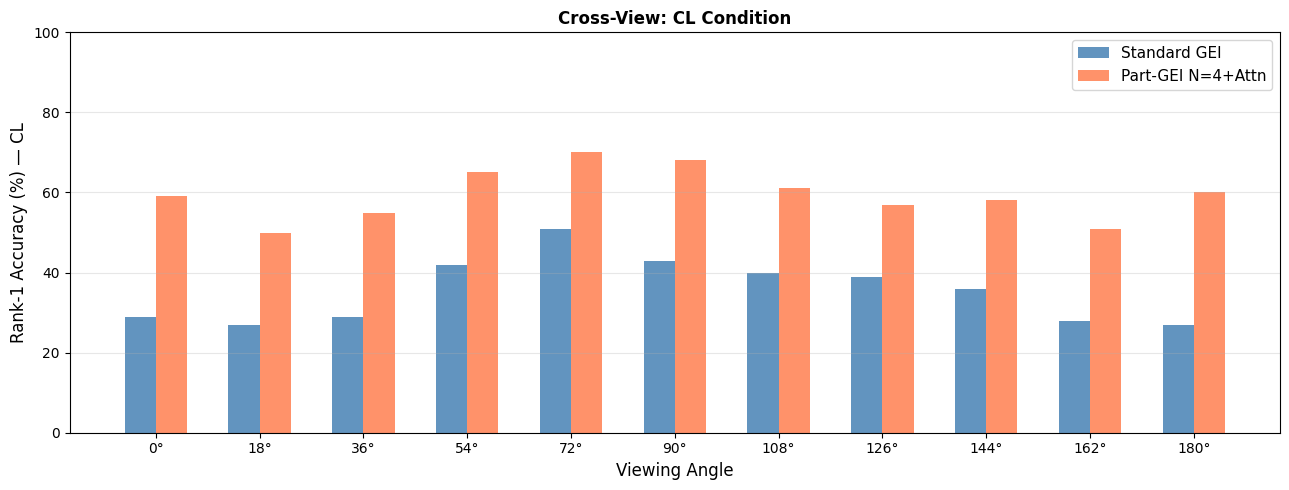

In [ ]:
print("Cross-view — CL...")
angle_base_cl, angle_part_cl = [], []

for ang in ANGLES:
    for res_list, mdl, mode, np_ in [
        (angle_base_cl, model_base, 'full',  1),
        (angle_part_cl, model_part, 'parts', N_PARTS),
    ]:
        gd = CASIABDataset(
            extract_path, TEST_SUBJECTS,
            GALLERY_SEQS, ANGLES,
            label_map=test_label_map,
            mode=mode, n_parts=np_
        )
        pd_ = CASIABDataset(
            extract_path, TEST_SUBJECTS,
            PROBE_CL, [ang],
            label_map=test_label_map,
            mode=mode, n_parts=np_
        )
        if len(pd_) > 0:
            r = evaluate_rank1(mdl, gd, pd_,
                               exclude_same_angle=False)
            res_list.append(r['CL'])
        else:
            res_list.append(0.)

angle_labels = [f"{int(a)}°" for a in ANGLES]
x = np.arange(len(ANGLES)); w = 0.3

fig, ax = plt.subplots(figsize=(13,5))
ax.bar(x-w/2, angle_base_cl, w,
       label='Standard GEI', color='steelblue', alpha=0.85)
ax.bar(x+w/2, angle_part_cl, w,
       label=f'Part-GEI N={N_PARTS}+Attn',
       color='coral', alpha=0.85)
ax.set_xticks(x); ax.set_xticklabels(angle_labels)
ax.set_xlabel('Viewing Angle', fontsize=12)
ax.set_ylabel('Rank-1 Accuracy (%) — CL', fontsize=12)
ax.set_title('Cross-View: CL Condition',
             fontsize=12, fontweight='bold')
ax.legend(fontsize=11); ax.set_ylim(0,100)
ax.grid(True,axis='y',alpha=0.3)
plt.tight_layout()
plt.savefig(
    '/content/drive/MyDrive/CASIA_B/crossview_CL.png',
    dpi=150, bbox_inches='tight'
)
plt.show()

Cross-view — BG...
  Loaded 2187 samples (0 skipped) [mode=full, n_parts=1]
  Loaded 100 samples (0 skipped) [mode=full, n_parts=1]
  Loaded 2187 samples (0 skipped) [mode=parts, n_parts=4]
  Loaded 100 samples (0 skipped) [mode=parts, n_parts=4]
  Loaded 2187 samples (0 skipped) [mode=full, n_parts=1]
  Loaded 100 samples (0 skipped) [mode=full, n_parts=1]
  Loaded 2187 samples (0 skipped) [mode=parts, n_parts=4]
  Loaded 100 samples (0 skipped) [mode=parts, n_parts=4]
  Loaded 2187 samples (0 skipped) [mode=full, n_parts=1]
  Loaded 100 samples (0 skipped) [mode=full, n_parts=1]
  Loaded 2187 samples (0 skipped) [mode=parts, n_parts=4]
  Loaded 100 samples (0 skipped) [mode=parts, n_parts=4]
  Loaded 2187 samples (0 skipped) [mode=full, n_parts=1]
  Loaded 99 samples (0 skipped) [mode=full, n_parts=1]
  Loaded 2187 samples (0 skipped) [mode=parts, n_parts=4]
  Loaded 99 samples (0 skipped) [mode=parts, n_parts=4]
  Loaded 2187 samples (0 skipped) [mode=full, n_parts=1]
  Loaded 100 s

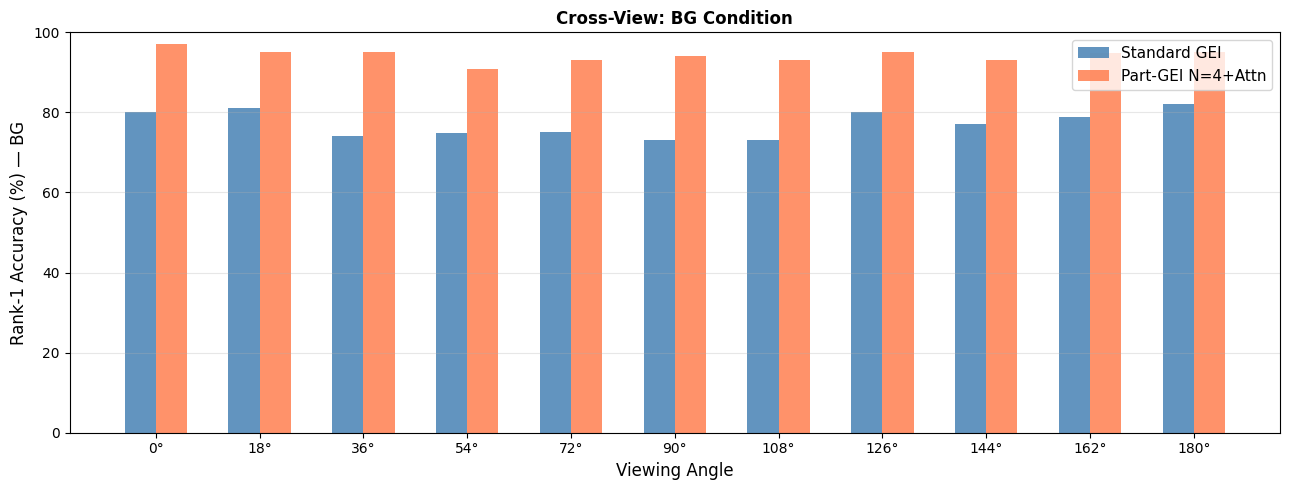

In [ ]:
print("Cross-view — BG...")
angle_base_bg, angle_part_bg = [], []

for ang in ANGLES:
    for res_list, mdl, mode, np_ in [
        (angle_base_bg, model_base, 'full',  1),
        (angle_part_bg, model_part, 'parts', N_PARTS),
    ]:
        gd = CASIABDataset(
            extract_path, TEST_SUBJECTS,
            GALLERY_SEQS, ANGLES,
            label_map=test_label_map,
            mode=mode, n_parts=np_
        )
        pd_ = CASIABDataset(
            extract_path, TEST_SUBJECTS,
            PROBE_BG, [ang],
            label_map=test_label_map,
            mode=mode, n_parts=np_
        )
        if len(pd_) > 0:
            r = evaluate_rank1(mdl, gd, pd_,
                               exclude_same_angle=False)
            res_list.append(r['BG'])
        else:
            res_list.append(0.)

fig, ax = plt.subplots(figsize=(13,5))
ax.bar(x-w/2, angle_base_bg, w,
       label='Standard GEI', color='steelblue', alpha=0.85)
ax.bar(x+w/2, angle_part_bg, w,
       label=f'Part-GEI N={N_PARTS}+Attn',
       color='coral', alpha=0.85)
ax.set_xticks(x); ax.set_xticklabels(angle_labels)
ax.set_xlabel('Viewing Angle', fontsize=12)
ax.set_ylabel('Rank-1 Accuracy (%) — BG', fontsize=12)
ax.set_title('Cross-View: BG Condition',
             fontsize=12, fontweight='bold')
ax.legend(fontsize=11); ax.set_ylim(0,100)
ax.grid(True,axis='y',alpha=0.3)
plt.tight_layout()
plt.savefig(
    '/content/drive/MyDrive/CASIA_B/crossview_BG.png',
    dpi=150, bbox_inches='tight'
)
plt.show()

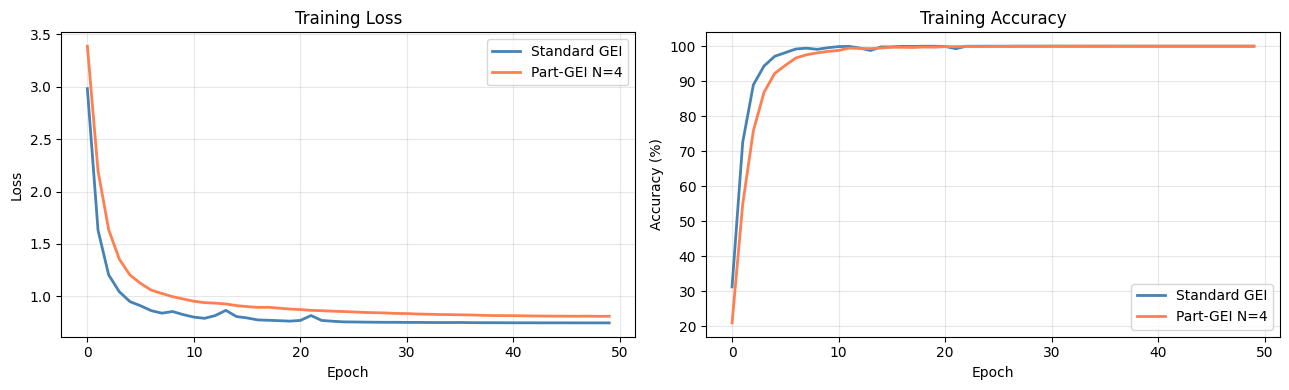

In [ ]:
fig, axes = plt.subplots(1,2,figsize=(13,4))
axes[0].plot(hist_base['loss'], label='Standard GEI',
             color='steelblue', linewidth=2)
axes[0].plot(hist_part['loss'], label=f'Part-GEI N={N_PARTS}',
             color='coral', linewidth=2)
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss')
axes[0].set_title('Training Loss')
axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(hist_base['acc'], label='Standard GEI',
             color='steelblue', linewidth=2)
axes[1].plot(hist_part['acc'], label=f'Part-GEI N={N_PARTS}',
             color='coral', linewidth=2)
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Accuracy (%)')
axes[1].set_title('Training Accuracy')
axes[1].legend(); axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(
    '/content/drive/MyDrive/CASIA_B/training_curves.png',
    dpi=150, bbox_inches='tight'
)
plt.show()

In [ ]:
print("\n" + "="*65)
print("FINAL RESULTS SUMMARY")
print("="*65)
print(f"{'Method':<40} {'NM':>6} {'BG':>6} {'CL':>6} {'Mean':>6}")
print("-"*65)
for name, r in [
    ('Standard GEI [Baseline]',             rank1_base),
    (f'Part-GEI N={N_PARTS}+Attn [Proposed]', rank1_part),
]:
    print(f"{name:<40} "
          f"{r['NM']:>6.2f} "
          f"{r['BG']:>6.2f} "
          f"{r['CL']:>6.2f} "
          f"{r['Mean']:>6.2f}")
print("="*65)
print("\nDelta (Proposed - Baseline):")
for c in ['NM','BG','CL','Mean']:
    d = rank1_part[c] - rank1_base[c]
    print(f"  {c}: {'+' if d>=0 else ''}{d:.2f}%")
print("="*65)

pd.DataFrame([
    {'Method': n,
     'NM (%)': round(r['NM'],2),
     'BG (%)': round(r['BG'],2),
     'CL (%)': round(r['CL'],2),
     'Mean (%)': round(r['Mean'],2)}
    for n,r in [
        ('Standard GEI [Baseline]', rank1_base),
        (f'Part-GEI N={N_PARTS}+Attn [Proposed]', rank1_part),
    ]
]).to_csv(
    '/content/drive/MyDrive/CASIA_B/final_summary.csv',
    index=False
)
print("All files saved to Drive.")


FINAL RESULTS SUMMARY
Method                                       NM     BG     CL   Mean
-----------------------------------------------------------------
Standard GEI [Baseline]                   93.82  72.13  33.82  66.59
Part-GEI N=4+Attn [Proposed]              99.00  91.44  52.55  80.99

Delta (Proposed - Baseline):
  NM: +5.18%
  BG: +19.31%
  CL: +18.73%
  Mean: +14.41%
All files saved to Drive.
